# CHƯƠNG 5. QUÁ TRÌNH KHAI THÁC DỮ LIỆU ĐIỂM CHUẨN

Bài toán chính: hồi quy điểm chuẩn quy đổi. Bổ trợ: phân loại nhóm điểm và nhị phân điểm >=24.

Train 2010–2023; chọn mô hình bằng validation 2024; khóa lựa chọn, refit 2010–2024 và đánh giá test 2025. Dữ liệu năm 2025 đã được sử dụng trong phân tích thăm dò; do đó đánh giá hiện tại là kiểm định hồi cứu, chưa phải kiểm định tiên nghiệm độc lập.

### Bước 1. Chuẩn bị môi trường

Nạp các thư viện phục vụ xử lý dữ liệu, huấn luyện và đánh giá mô hình; đồng thời xác định đường dẫn đến dữ liệu nguồn và thư mục lưu kết quả thực nghiệm.

In [1]:
from pathlib import Path
import sys, json, inspect
import pandas as pd
from IPython.display import display, Image
candidates = [Path.cwd(), *Path.cwd().parents]
mining_dir = next((x for b in candidates for x in [b,b/'DataMining'] if (x/'scripts/preprocess.py').is_file()),None)
if mining_dir is None:
    mining_dir = next(Path.cwd().rglob('DataMining'))
sys.path.insert(0,str(mining_dir/'scripts'))
from preprocess import (SCORES_PATH,MAJORS_PATH,FEATURES,GRAIN,load_and_preprocess_data,
    split_dataset,make_encoder,resolve_major,add_history_features)
from train_models import model_catalog,make_model,train_and_validate,refit_and_test
from evaluate import plot_eda,plot_results,previous_year_baseline,score_model
from run_all import export_summary
output_dir = mining_dir/'results'
output_dir.mkdir(parents=True,exist_ok=True)
print('Nguồn:',SCORES_PATH)
print('Output:',output_dir)

Nguồn: D:\Study\University\OLAP\Đồ án\IS217.R11-OLAP\Data\cleaned\cleaned-cutoff-scores.csv
Output: d:\Study\University\OLAP\Đồ án\IS217.R11-OLAP\DataMining\results


*Hình 5.1. Nạp thư viện và xác định đường dẫn.*

## 5.1. Mô tả dữ liệu

Một quan sát sau xử lý: trường–mã chương trình–tên chương trình–tập tổ hợp–năm–phương thức. Điểm mục tiêu lấy từ cột đã quy đổi; giữ nguyên cả điểm gốc và điểm quy đổi của nguồn.

### Bước 2. Đọc và xem dữ liệu

Đọc bộ dữ liệu điểm chuẩn từ tệp CSV, xác định số dòng, số thuộc tính và quan sát các bản ghi đầu tiên để nắm cấu trúc dữ liệu đầu vào.

In [2]:
raw = pd.read_csv(SCORES_PATH,dtype={'school_id':str,'score_code':str})
print('Kích thước:',raw.shape)
display(raw[['school_id','score_code','score_name','score_year','score_mark','score_converted_mark']].head())

Kích thước: (111005, 14)


,school_id,score_code,score_name,score_year,score_mark,score_converted_mark
0,CKC,6510304,Công nghệ Kỹ thuật Cơ điện tử,2018,16.00,16.00
1,CKC,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,2025,23.00,17.25
2,CKC,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,2025,17.25,17.25
3,CKC,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,2025,500.00,500.00
4,CES,6510304,Công nghệ kỹ thuật cơ điện tử,2024,13.00,13.00


*Hình 5.2. Dữ liệu tuyển sinh đầu vào.*

### Bước 3. Kiểm tra chất lượng

Kiểm tra kiểu dữ liệu, số lượng giá trị thiếu và bản ghi trùng lặp. Kết quả kiểm tra là cơ sở xác định các vấn đề cần xử lý trước khi xây dựng mô hình.

In [3]:
display(pd.DataFrame({'Kiểu':raw.dtypes.astype(str),'Thiếu':raw.isna().sum()}))
print('Trùng hoàn toàn trong nguồn:',raw.duplicated().sum())
print('Số dòng THPT:',raw.score_admission_name.eq('Điểm thi THPT').sum())

,Kiểu,Thiếu
school_id,str,0
school_name,str,0
school_type,str,0
school_short_name,str,3103
province_id,int64,0
province_name,str,0
score_code,str,0
score_name,str,0
score_blocks,str,36359
score_mark,float64,0


Trùng hoàn toàn trong nguồn: 1158
Số dòng THPT: 60783


*Hình 5.3. Dữ liệu thiếu và trùng lặp.*

## 5.2. Tiền xử lý

Không quy đổi lại cột điểm đã quy đổi. Tách các dòng mâu thuẫn trên cùng khóa, ghi chú hệ số chưa xác nhận và phương thức kết hợp để rà soát. Khoảng 10–30 là phạm vi nghiên cứu, không phải khẳng định mọi điểm ngoài khoảng là sai. Quy tắc dựa trên ghi chú chưa thay thế xác minh quy chế từng trường.

### Bước 4. Làm sạch có nhật ký

Lọc dữ liệu thuộc phương thức xét tuyển bằng điểm thi THPT và áp dụng các quy tắc về phạm vi điểm, định danh chương trình và tính nhất quán của bản ghi. Các trường hợp chưa đủ điều kiện được tách để rà soát; số lượng quan sát qua từng bước được ghi nhận để truy vết.

In [4]:
df,audit = load_and_preprocess_data(output_dir=output_dir/'data')
keys = ['source_rows','thpt_rows','exact_duplicates_removed','quality_excluded_rows',
    'conflicting_score_rows_excluded','same_grain_same_score_duplicates_removed','final_rows']
display(pd.DataFrame({'Bước':keys,'Số dòng':[audit[k] for k in keys]}))
print('Trùng khóa còn lại:',df.duplicated(GRAIN).sum())

Nguồn: 111,005; THPT: 60,783; tập nghiên cứu: 50,245


,Bước,Số dòng
0,source_rows,111005
1,thpt_rows,60783
2,exact_duplicates_removed,909
3,quality_excluded_rows,3418
4,conflicting_score_rows_excluded,6119
5,same_grain_same_score_duplicates_removed,92
6,final_rows,50245


Trùng khóa còn lại: 0


*Hình 5.4. Số dòng qua từng bước xử lý.*

### Bước 5. Đối chiếu điểm quy đổi

Đối chiếu điểm gốc, điểm quy đổi và ghi chú xét tuyển nhằm kiểm tra biến mục tiêu sử dụng trong thực nghiệm. Cột điểm đã quy đổi của nguồn được giữ nguyên, tránh áp dụng phép quy đổi thêm một lần.

In [5]:
display(df.loc[df.score_mark.ne(df.target_score),['school_name','score_name','score_year',
    'score_mark','score_converted_mark','target_score','score_introtext']].head(8))
display(pd.Series(audit['quality_exclusion_reasons'],name='Số dòng').to_frame())

,school_name,score_name,score_year,score_mark,score_converted_mark,target_score,score_introtext
87,Trường Đại Học Nghệ Thuật Huế,Hội họa,2010,24.0,18.000,18.000,Các môn năng khiếu nhân hệ số 2
88,Trường Đại Học Nghệ Thuật Huế,Điêu khắc,2010,27.5,20.625,20.625,Các môn năng khiếu nhân hệ số 2
300,Trường Đại Học Quốc Tế Hồng Bàng,Thiết kế kinh doanh thời trang,2010,15.0,11.250,11.250,năng khiếu hệ số 2
301,Trường Đại Học Quốc Tế Hồng Bàng,"Trang trí nội ngoại thất, Resort center",2010,15.0,11.250,11.250,năng khiếu hệ số 2
372,Trường Đại Học Mở Hà Nội,Quản trị kinh doanh du lịch và khách sạn,2010,18.5,13.875,13.875,Tiếng Anh hệ số 2
373,Trường Đại Học Mở Hà Nội,Hướng dẫn du lịch,2010,18.0,13.500,13.500,Tiếng Anh hệ số 2
820,Đại Học Duy Tân,Kiến trúc công trình,2011,17.0,12.750,12.750,Nghành Kiến trúc ( Môn Vẽ nhân hệ số 2)
922,Trường Đại Học Phương Đông,Kiến trúc,2011,19.0,14.250,14.250,Môn vẽ nhân hệ số 2


,Số dòng
"Điểm ngoài phạm vi [10, 30] hoặc thiếu",3283
Ghi chú hệ số chưa xác nhận quy đổi,105
"Điểm ngoài phạm vi [10, 30] hoặc thiếu; Ghi chú hệ số chưa xác nhận quy đổi",30


*Hình 5.5. Điểm gốc, điểm quy đổi và lý do loại.*

### Bước 6. Ánh xạ ngành

Liên kết chương trình tuyển sinh với danh mục nhóm ngành dựa trên mã và tên ngành. Các nhóm phù hợp được giữ đầy đủ; trường hợp chưa xác định được ánh xạ được ghi nhận riêng thay vì gán nhóm theo thứ tự bản ghi.

In [6]:
print(inspect.getsource(resolve_major))
display(pd.Series(audit['major_mapping_status'],name='Số dòng').to_frame())
display(df[['score_code','score_name','major_groups','major_mapping_status']].head())

def resolve_major(code, program_name, candidates):
    """Khớp nhóm ngành dựa trên mã và tên ngành để tránh gán nhầm."""
    options = candidates.get(str(code).strip(), set())
    exact_matches = {group for name, group in options if name == program_name}
    if exact_matches:
        return ' | '.join(sorted(exact_matches)), 'Khớp mã và tên'
    
    unique_names = {name for name, _ in options}
    if len(unique_names) == 1:
        return ' | '.join(sorted({g for _, g in options})), 'Mã có một tên ngành'
    if options:
        return 'Chưa xác định', 'Mã nhiều tên ngành, chưa khớp tên'
    return 'Chưa xác định', 'Không có mã trong danh mục'



,Số dòng
Khớp mã và tên,30983
Mã có một tên ngành,16054
"Mã nhiều tên ngành, chưa khớp tên",3208


,score_code,score_name,major_groups,major_mapping_status
0,120,Kỹ thuật nhiệt lạnh,Mỏ - Địa chất,Mã có một tên ngành
1,210,"điện tử viễn thông , kỹ thuật y sinh,",Công nghiệp bán dẫn | Ô tô - Cơ khí - Chế tạo ...,Mã có một tên ngành
2,220,"công nghệ thông tin,",Mỏ - Địa chất,Mã có một tên ngành
3,401,Quản trị kinh doanh,Kinh tế - Quản trị kinh doanh - Thương Mại,Mã có một tên ngành
4,401,Quản trị kinh doanh.,Kinh tế - Quản trị kinh doanh - Thương Mại,Mã có một tên ngành


*Hình 5.6. Ánh xạ nhóm ngành có kiểm soát.*

### Bước 7. Tổ hợp môn và nhãn

Chuẩn hóa danh sách tổ hợp xét tuyển bằng cách loại mã trùng và sắp xếp các tổ hợp. Đồng thời, tạo nhãn phân loại bốn nhóm điểm và nhãn nhị phân từ 24 điểm trở lên theo quy ước của thực nghiệm.

In [7]:
display(df[['score_blocks','block_set','target_score','competition_label','is_high_score']].head(10))
print('Quy ước đồ án: <18; [18,22); [22,25); >=25.')
print('Nhị phân >=24 là bài toán riêng, không đồng nhất với lớp >=25.')

,score_blocks,block_set,target_score,competition_label,is_high_score
0,NaN,Chưa xác định,18.0,Từ 18 đến dưới 22,0
1,NaN,Chưa xác định,21.0,Từ 18 đến dưới 22,0
2,NaN,Chưa xác định,21.0,Từ 18 đến dưới 22,0
3,NaN,Chưa xác định,17.0,Dưới 18,0
4,NaN,Chưa xác định,21.0,Từ 18 đến dưới 22,0
5,NaN,Chưa xác định,17.0,Dưới 18,0
6,NaN,Chưa xác định,18.0,Từ 18 đến dưới 22,0
7,NaN,Chưa xác định,17.5,Dưới 18,0
8,NaN,Chưa xác định,14.0,Dưới 18,0
9,NaN,Chưa xác định,16.0,Dưới 18,0


Quy ước đồ án: <18; [18,22); [22,25); >=25.
Nhị phân >=24 là bài toán riêng, không đồng nhất với lớp >=25.


*Hình 5.7. Tổ hợp đầy đủ và nhóm điểm.*

### Bước 8. Thống kê mô tả

Tính các chỉ tiêu thống kê của điểm chuẩn sau tiền xử lý, gồm số quan sát, trung bình, độ lệch chuẩn, các tứ phân vị và giá trị nhỏ nhất, lớn nhất. Thống kê theo năm cho biết quy mô dữ liệu của từng kỳ tuyển sinh.

In [8]:
display(df.target_score.describe().to_frame('Điểm quy đổi'))
display(df.groupby('score_year').size().to_frame('Số bản ghi'))

,Điểm quy đổi
count,50245.000000
mean,19.103321
std,4.359383
min,10.000000
25%,15.000000
50%,18.000000
75%,22.920000
max,30.000000


,Số bản ghi
score_year,
2010,754
2011,809
2012,1065
2013,1334
2014,1493
2015,2299
2016,2308
2017,3167
2018,3401


*Hình 5.8. Thống kê điểm chuẩn sau xử lý.*

### Bước 9. Trực quan phân bố

Trực quan hóa phân bố điểm chuẩn, số quan sát theo năm và số lượng bản ghi trong từng nhóm điểm. Các biểu đồ hỗ trợ nhận diện đặc điểm phân bố và mức độ mất cân bằng giữa các nhóm.

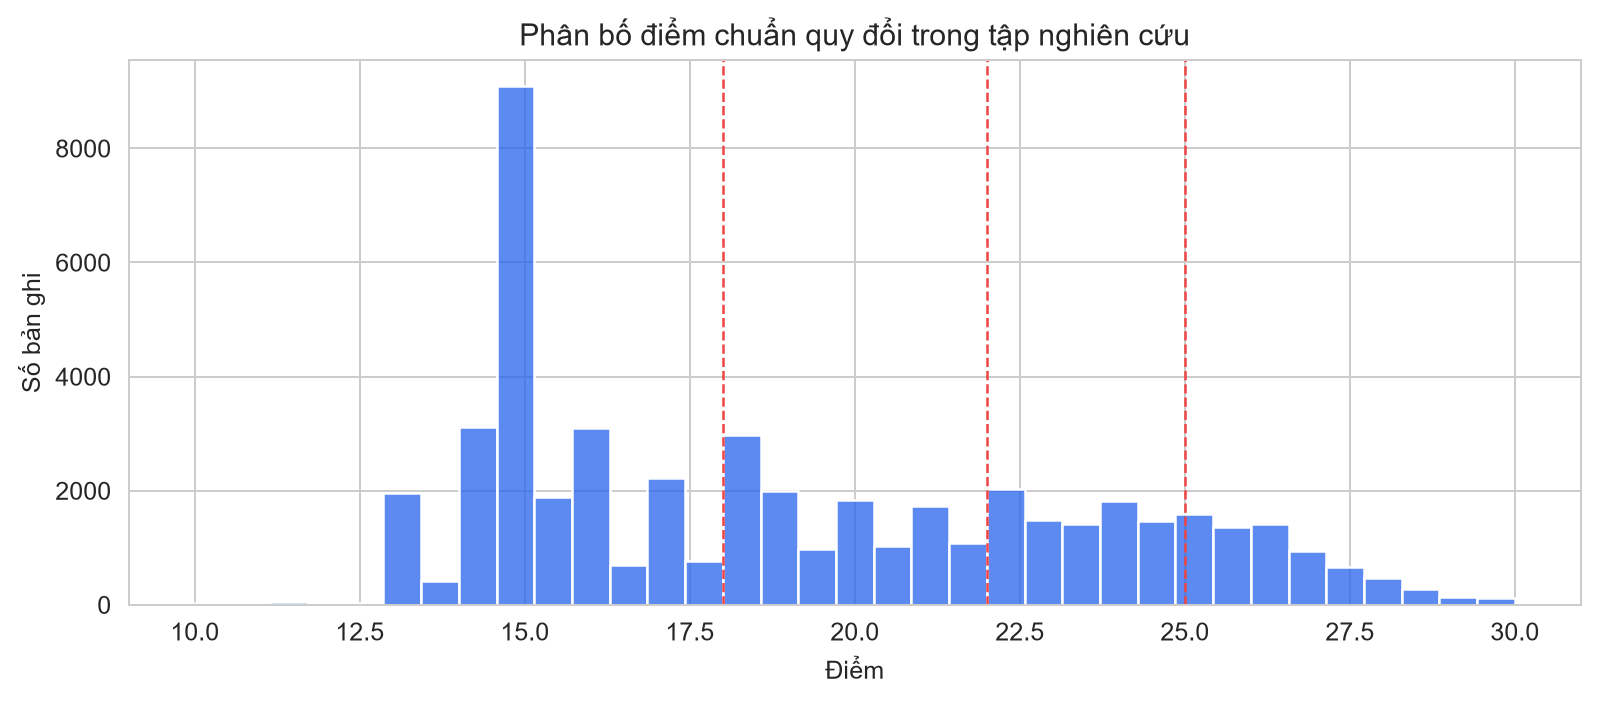

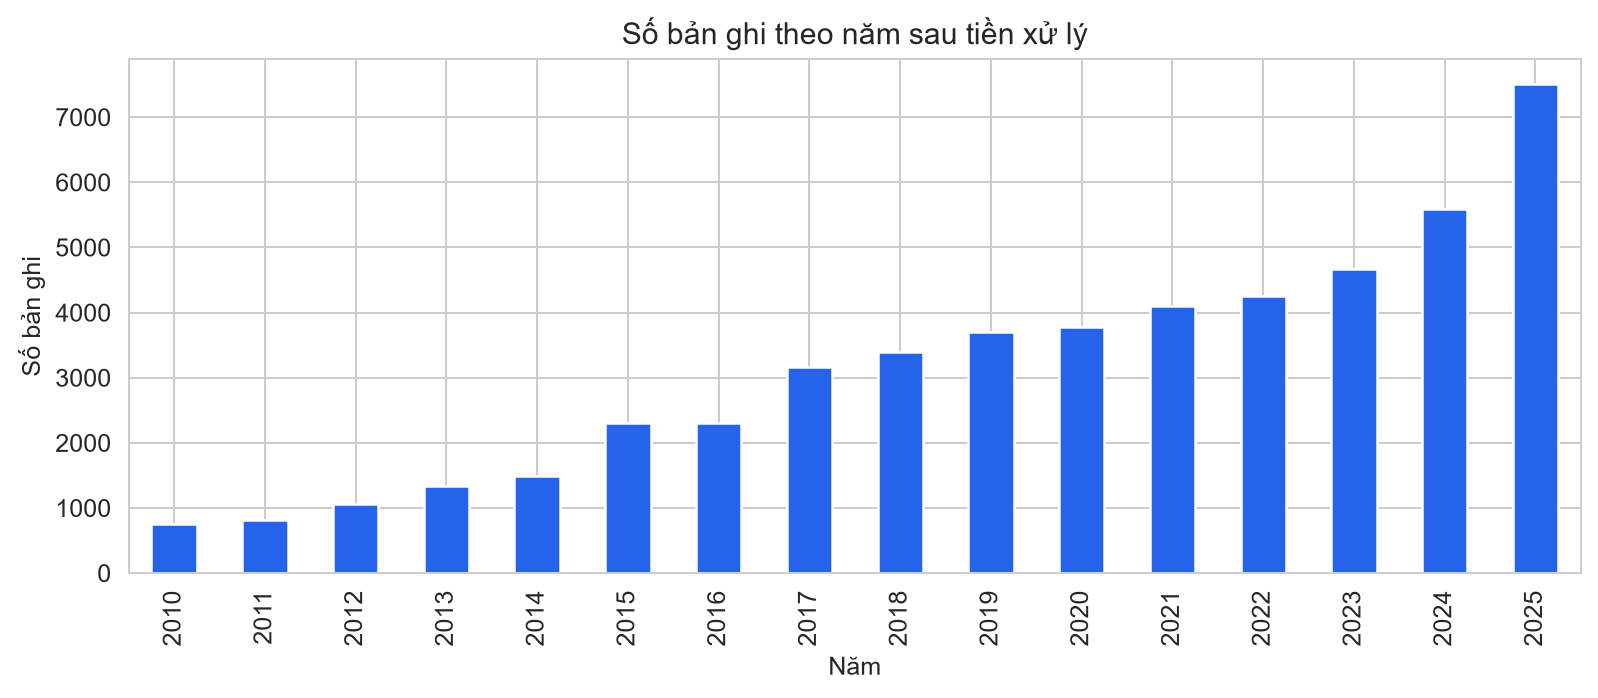

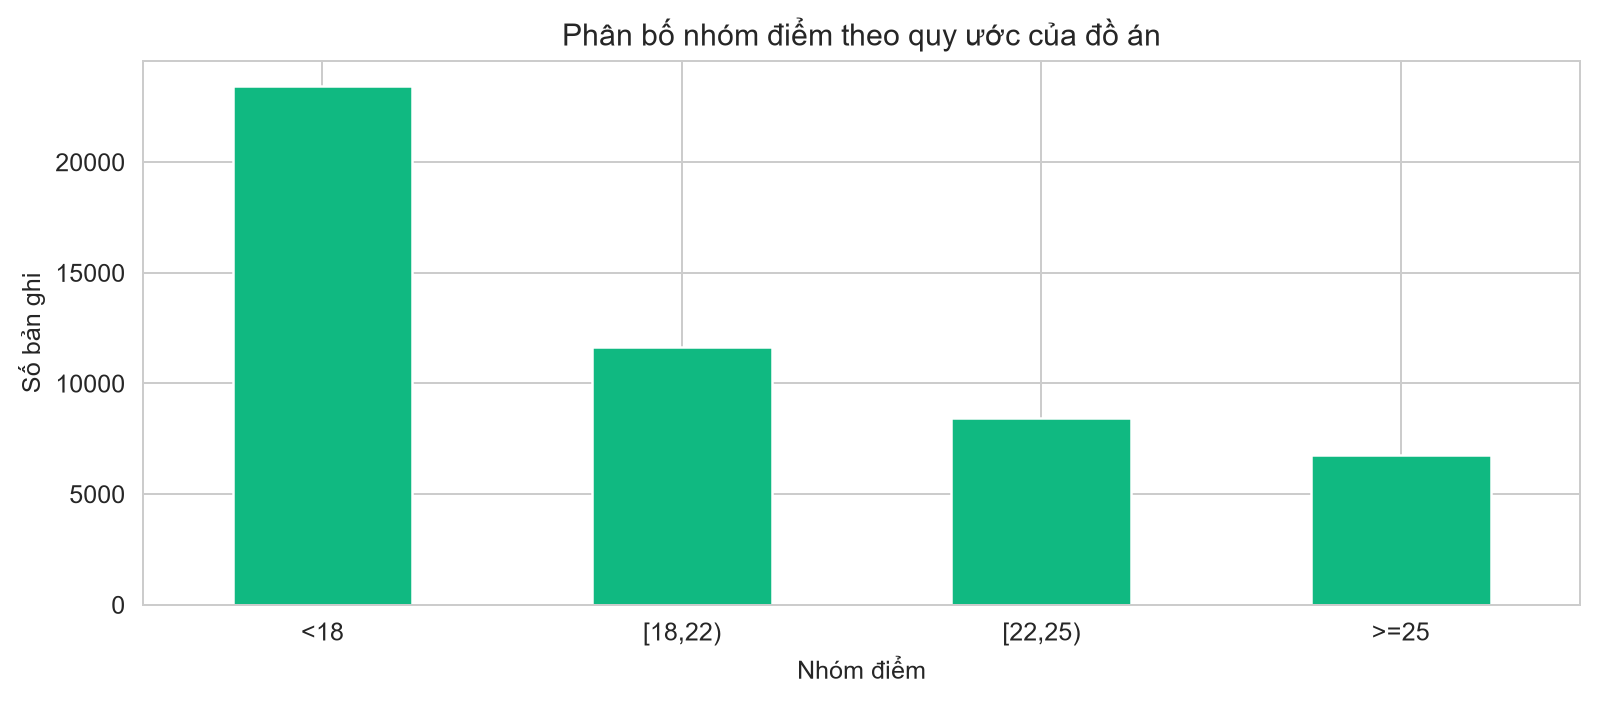

In [9]:
plot_eda(df,output_dir/'images')
for filename in ['01_score_distribution.png','02_records_by_year.png','03_class_distribution.png']:
    display(Image(filename=str(output_dir/'images'/filename),width=850))

*Hình 5.9–5.11. Phân bố điểm, năm và nhóm điểm.*

## 5.3. Chuẩn bị dữ liệu mô hình

Chỉ lấy điểm của đúng năm t−1, cùng chương trình và tập tổ hợp. Điền thiếu, mã hóa chỉ học từ train tương ứng. Ordinal Encoding tạo thứ tự số giả cho danh mục; đây là hạn chế cần ghi nhận.

### Bước 10. Đặc trưng lịch sử

Tạo đặc trưng điểm chuẩn của đúng năm liền trước đối với cùng trường, chương trình và tập tổ hợp xét tuyển. Việc liên kết chỉ sử dụng dữ liệu quá khứ, đồng thời bổ sung biến đánh dấu những quan sát có thông tin lịch sử.

In [10]:
print(inspect.getsource(add_history_features))
display(df.loc[df.has_previous_year_score.eq(1),['school_id','score_name','score_year','previous_year_score','target_score']].tail(8))
print('Tỷ lệ có lịch sử:',round(df.has_previous_year_score.mean()*100,2),'%')

def add_history_features(df):
    """Nối điểm chuẩn của đúng năm liền trước cho từng ngành của từng trường."""
    history = df[PROGRAM_KEY + ['score_year', 'target_score']].copy()
    history['score_year'] += 1
    history = history.rename(columns={'target_score': 'previous_year_score'})
    
    merged = df.merge(history, on=PROGRAM_KEY + ['score_year'], how='left', validate='one_to_one')
    merged['has_previous_year_score'] = merged['previous_year_score'].notna().astype(int)
    return merged



,school_id,score_name,score_year,previous_year_score,target_score
50196,YHB,Y học dự phòng,2025,22.94,17.0
50197,YHB,Y học cổ truyền,2025,25.29,23.5
50211,YHB,Y tế công cộng,2025,24.30,21.2
50233,YTB,Y khoa,2025,26.17,24.6
50234,YTB,Y học dự phòng,2025,19.15,17.0
50235,YTB,Y học cổ truyền,2025,23.00,19.0
50236,YTB,Dược học,2025,24.00,19.5
50237,YTB,Điều dưỡng,2025,20.00,17.0


Tỷ lệ có lịch sử: 39.78 %


*Hình 5.12. Điểm của đúng năm liền trước.*

### Bước 11. Xác định đầu vào và mục tiêu

Xác định tập đặc trưng đầu vào và biến mục tiêu cho ba bài toán hồi quy, phân loại nhóm điểm và phân loại nhị phân. Điểm chuẩn cùng năm và các nhãn suy ra từ điểm này được loại khỏi đầu vào để hạn chế rò rỉ thông tin mục tiêu.

In [11]:
print('X:',FEATURES)
print('y: target_score / competition_class / is_high_score')
assert not set(FEATURES)&{'target_score','score_mark','score_converted_mark','competition_class','is_high_score'}
display(df[FEATURES].head())

X: ['school_id', 'school_type', 'province_name', 'program_name', 'major_groups', 'block_set', 'score_year', 'previous_year_score', 'has_previous_year_score']
y: target_score / competition_class / is_high_score


,school_id,school_type,province_name,program_name,major_groups,block_set,score_year,previous_year_score,has_previous_year_score
0,BKA,Đại học,Hà Nội,kỹ thuật nhiệt lạnh,Mỏ - Địa chất,Chưa xác định,2010,NaN,0
1,BKA,Đại học,Hà Nội,"điện tử viễn thông , kỹ thuật y sinh,",Công nghiệp bán dẫn | Ô tô - Cơ khí - Chế tạo ...,Chưa xác định,2010,NaN,0
2,BKA,Đại học,Hà Nội,"công nghệ thông tin,",Mỏ - Địa chất,Chưa xác định,2010,NaN,0
3,BVH,Đại học,Hà Nội,quản trị kinh doanh,Kinh tế - Quản trị kinh doanh - Thương Mại,Chưa xác định,2010,NaN,0
4,BVH,Đại học,Hà Nội,quản trị kinh doanh.,Kinh tế - Quản trị kinh doanh - Thương Mại,Chưa xác định,2010,NaN,0


*Hình 5.13. Tách X và y.*

### Bước 12. Chia theo thời gian

Phân chia dữ liệu theo thứ tự thời gian: giai đoạn 2010–2023 dùng để huấn luyện, năm 2024 dùng để xác thực và năm 2025 dùng để kiểm tra. Cách chia này mô phỏng việc sử dụng thông tin quá khứ để dự báo cho năm tiếp theo.

In [12]:
splits = split_dataset(df)
display(pd.DataFrame([{'Tập':name,'Số dòng':len(part),
        'Từ năm':part.score_year.min(),'Đến năm':part.score_year.max()} for name,part in splits.items()]))
print('Record ID train giao test:',len(set(splits['train'].record_id)&set(splits['test'].record_id)))

Train <=2023: 37,136; validation 2024: 5,595; test 2025: 7,514


,Tập,Số dòng,Từ năm,Đến năm
0,train,37136,2010,2023
1,validation,5595,2024,2024
2,test,7514,2025,2025


Record ID train giao test: 0


*Hình 5.14. Train, validation và test.*

### Bước 13. Mã hóa từ train

Xây dựng bộ tiền xử lý gồm mã hóa thuộc tính danh mục và điền giá trị số còn thiếu. Các tham số chỉ được học từ tập huấn luyện; danh mục chưa xuất hiện trong tập này được biểu diễn bằng mã -1.

In [13]:
encoder = make_encoder()
X_train = encoder.fit_transform(splits['train'][FEATURES])
X_validation = encoder.transform(splits['validation'][FEATURES])
print('Train:',X_train.shape,'Validation:',X_validation.shape)
print(inspect.getsource(make_encoder))

Train: (37136, 9) Validation: (5595, 9)
def make_encoder():
    """Tạo bộ tiền xử lý ColumnTransformer mã hóa dữ liệu đầu vào."""
    categorical_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='Chưa xác định')),
        ('encode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ])
    return ColumnTransformer([
        ('categorical', categorical_pipe, CATEGORICAL_FEATURES),
        ('numeric', SimpleImputer(strategy='median', keep_empty_features=True), NUMERIC_FEATURES)
    ], verbose_feature_names_out=False)



*Hình 5.15. Mã hóa đặc trưng và xử lý danh mục mới.*

## 5.4. Huấn luyện và lựa chọn trên validation

Hồi quy là bài toán chính. Các cấu hình nằm trong `model_catalog()` dùng chung với CLI. Baseline gồm trung vị, lớp phổ biến nhất và điểm năm trước. Không chọn lại mô hình theo test.

### Bước 14. Cấu hình thuật toán

Thiết lập cấu hình các thuật toán và mô hình cơ sở trong một danh mục dùng chung. Các tham số như số cây, độ sâu tối đa, tốc độ học và hạt giống ngẫu nhiên được khai báo rõ để bảo đảm khả năng tái lập thực nghiệm.

In [14]:
for task,models in model_catalog().items():
    print(task)
    for name,model in models.items(): print(name,model)
print(inspect.getsource(make_model))

regression
Median baseline DummyRegressor(strategy='median')
Random Forest RandomForestRegressor(max_depth=16, min_samples_leaf=3, n_jobs=1,
                      random_state=42)
XGBoost XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=4, num_parallel_tree=None, ...)
classification
Majority baseline DummyClassifier(strategy='most_freque

*Hình 5.16. Tham số dùng chung cho các mô hình.*

### Bước 15. Huấn luyện và đánh giá năm 2024

Huấn luyện các mô hình trên dữ liệu giai đoạn 2010–2023 và đánh giá trên tập xác thực năm 2024. Mô hình hồi quy được lựa chọn theo MAE, mô hình phân loại nhóm điểm theo Macro F1 và mô hình nhị phân theo ROC AUC.

In [15]:
validated,validation_metrics,winners = train_and_validate(splits,verbose=False)
row = previous_year_baseline(splits['train'],splits['validation']);row['split']='validation_2024'
validation_metrics = pd.concat([validation_metrics,pd.DataFrame([row])],ignore_index=True)
display(validation_metrics[['Task','Model','MAE','RMSE','R2','Accuracy','Macro F1','ROC AUC']])
print('Chọn bằng validation:',winners)


,Task,Model,MAE,RMSE,R2,Accuracy,Macro F1,ROC AUC
0,regression,Median baseline,4.563227,5.522770,-0.519029,NaN,NaN,NaN
1,regression,Random Forest,1.770748,2.485357,0.692369,NaN,NaN,NaN
2,regression,XGBoost,1.686626,2.335537,0.728340,NaN,NaN,NaN
3,classification,Majority baseline,NaN,NaN,NaN,0.355675,0.131180,NaN
4,classification,Decision Tree,NaN,NaN,NaN,0.623056,0.576721,NaN
5,classification,Random Forest,NaN,NaN,NaN,0.681680,0.643241,NaN
6,classification,XGBoost,NaN,NaN,NaN,0.670777,0.628509,NaN
7,classification,LightGBM,NaN,NaN,NaN,0.680608,0.636911,NaN
8,binary,Decision Tree,NaN,NaN,NaN,0.813762,0.766884,0.895848
9,binary,Random Forest,NaN,NaN,NaN,0.833065,0.791380,0.928827


Chọn bằng validation: {'regression': 'XGBoost', 'classification': 'Random Forest', 'binary': 'XGBoost'}


*Hình 5.17. Kết quả validation và mô hình được chọn.*

### Bước 16. Minh họa fit, predict, evaluate

Minh họa quy trình huấn luyện, dự đoán và đánh giá bằng mô hình Random Forest hồi quy. Điểm dự đoán được đối chiếu với điểm thực tế của tập xác thực, kèm các chỉ số đánh giá tương ứng.

In [16]:
example = make_model(model_catalog()['regression']['Random Forest'])
example.fit(splits['train'][FEATURES],splits['train'].target_score)
y_pred_validation = example.predict(splits['validation'][FEATURES])
print(score_model(example,splits['validation'],'regression','Random Forest'))
display(pd.DataFrame({'Thực tế':splits['validation'].target_score.to_numpy()[:8],'Dự đoán':y_pred_validation[:8]}))

{'Task': 'regression', 'Model': 'Random Forest', 'Samples': 5595, 'MAE': 1.7707483418500916, 'RMSE': 2.4853570663322997, 'R2': 0.6923693906728405}


,Thực tế,Dự đoán
0,18.69,25.145664
1,18.75,25.236001
2,20.85,25.236001
3,17.50,24.965853
4,21.17,25.212443
5,19.39,25.212443
6,23.50,25.212443
7,20.71,25.212443


*Hình 5.18. Huấn luyện và dự đoán Random Forest.*

## 5.5. Đánh giá cuối trên năm 2025

Khóa lựa chọn trước khi refit trên 2010–2024. Báo cáo toàn bộ kết quả, nhưng mô hình được chọn vẫn là mô hình thắng trên validation.

### Bước 17. Refit và kiểm tra năm 2025

Sau khi cố định lựa chọn từ tập xác thực, huấn luyện lại các cấu hình trên dữ liệu giai đoạn 2010–2024 và đánh giá trên năm 2025. Kết quả kiểm tra được báo cáo cho toàn bộ mô hình và không được dùng để thay đổi lựa chọn trước đó.

In [17]:
final,test_metrics = refit_and_test(splits,validated,verbose=False)
history = pd.concat([splits['train'],splits['validation']],ignore_index=True)
row = previous_year_baseline(history,splits['test']);row['split']='test_2025'
test_metrics = pd.concat([test_metrics,pd.DataFrame([row])],ignore_index=True)
display(test_metrics[['Task','Model','MAE','RMSE','R2','Accuracy','Macro F1','ROC AUC']])

,Task,Model,MAE,RMSE,R2,Accuracy,Macro F1,ROC AUC
0,regression,Median baseline,4.350806,5.118850,-0.399094,NaN,NaN,NaN
1,regression,Random Forest,2.609553,3.290195,0.421977,NaN,NaN,NaN
2,regression,XGBoost,2.602172,3.174374,0.461955,NaN,NaN,NaN
3,classification,Majority baseline,NaN,NaN,NaN,0.316875,0.120313,NaN
4,classification,Decision Tree,NaN,NaN,NaN,0.459010,0.424431,NaN
5,classification,Random Forest,NaN,NaN,NaN,0.495475,0.461744,NaN
6,classification,XGBoost,NaN,NaN,NaN,0.493346,0.449576,NaN
7,classification,LightGBM,NaN,NaN,NaN,0.507852,0.472773,NaN
8,binary,Decision Tree,NaN,NaN,NaN,0.718126,0.657841,0.754129
9,binary,Random Forest,NaN,NaN,NaN,0.756455,0.715731,0.821814


*Hình 5.19. Kết quả test theo thời gian.*

### Bước 18. Phân tích hồi quy

Phân tích mô hình hồi quy được chọn thông qua biểu đồ điểm thực tế–dự đoán, phân bố sai số và so sánh MAE với các mô hình cơ sở. Các kết quả phản ánh mức độ sai lệch của dự báo trên tập kiểm tra năm 2025.

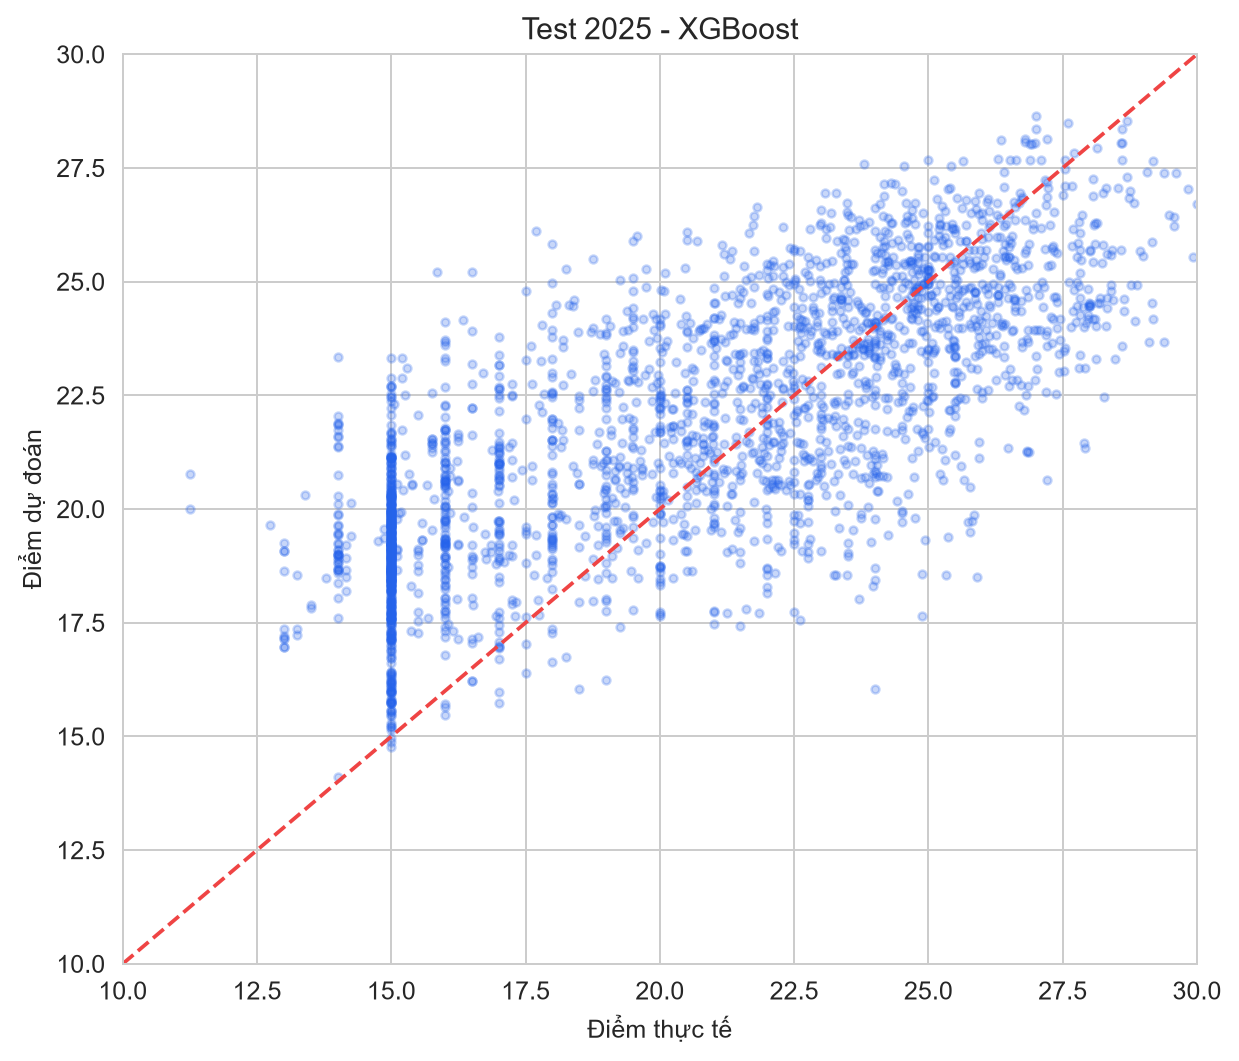

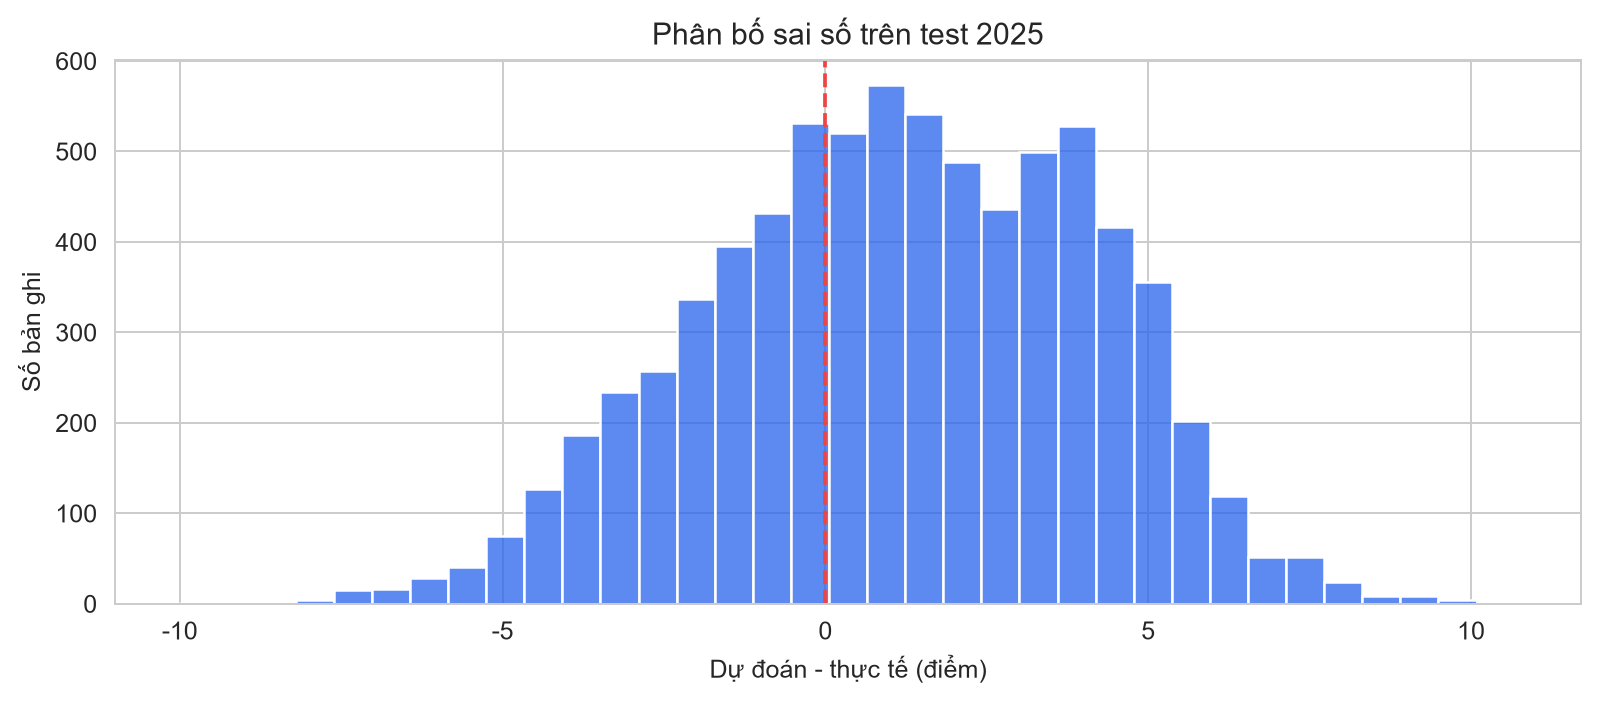

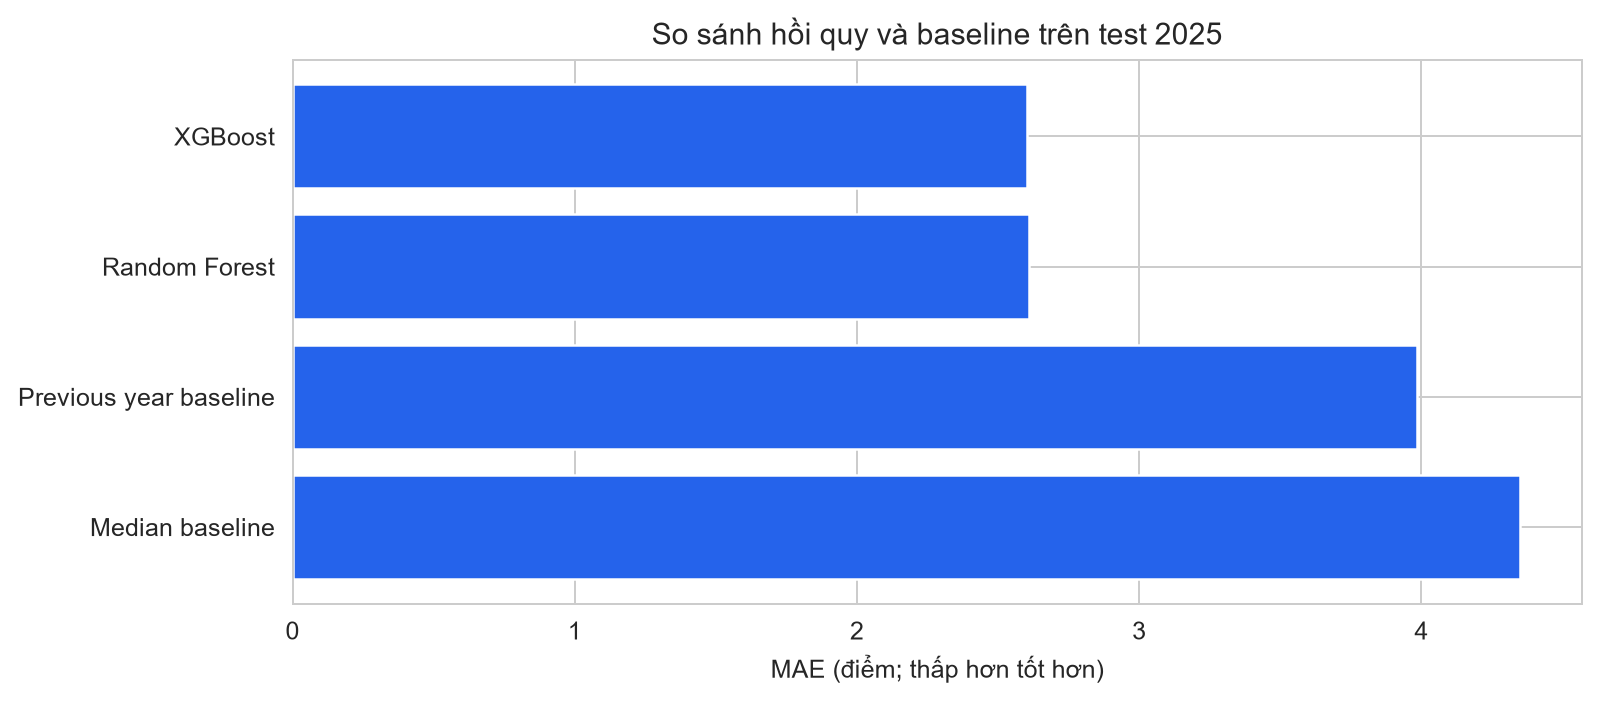

In [18]:
predictions,class_report,importance = plot_results(final,validated,splits,validation_metrics,test_metrics,winners,output_dir/'images')
for filename in ['04_actual_vs_predicted.png','05_residual_distribution.png','06_regression_comparison.png']:
    display(Image(filename=str(output_dir/'images'/filename),width=850))

*Hình 5.20–5.22. Điểm dự đoán, sai số và baseline.*

### Bước 19. Phân loại nhóm điểm

Đánh giá khả năng phân biệt bốn nhóm điểm bằng ma trận nhầm lẫn, Accuracy, Macro F1 và độ thu hồi của từng lớp. Kết quả cho phép xác định các nhóm còn bị nhầm lẫn và so sánh hiệu năng giữa các thuật toán.

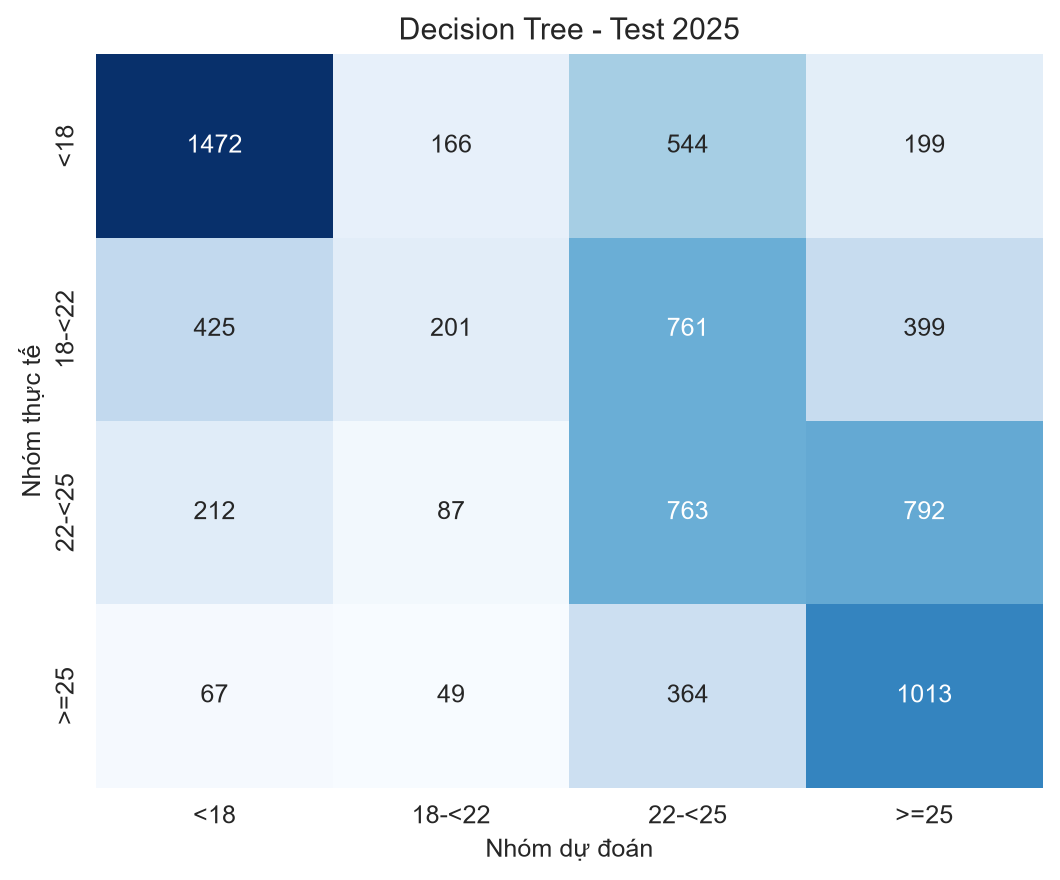

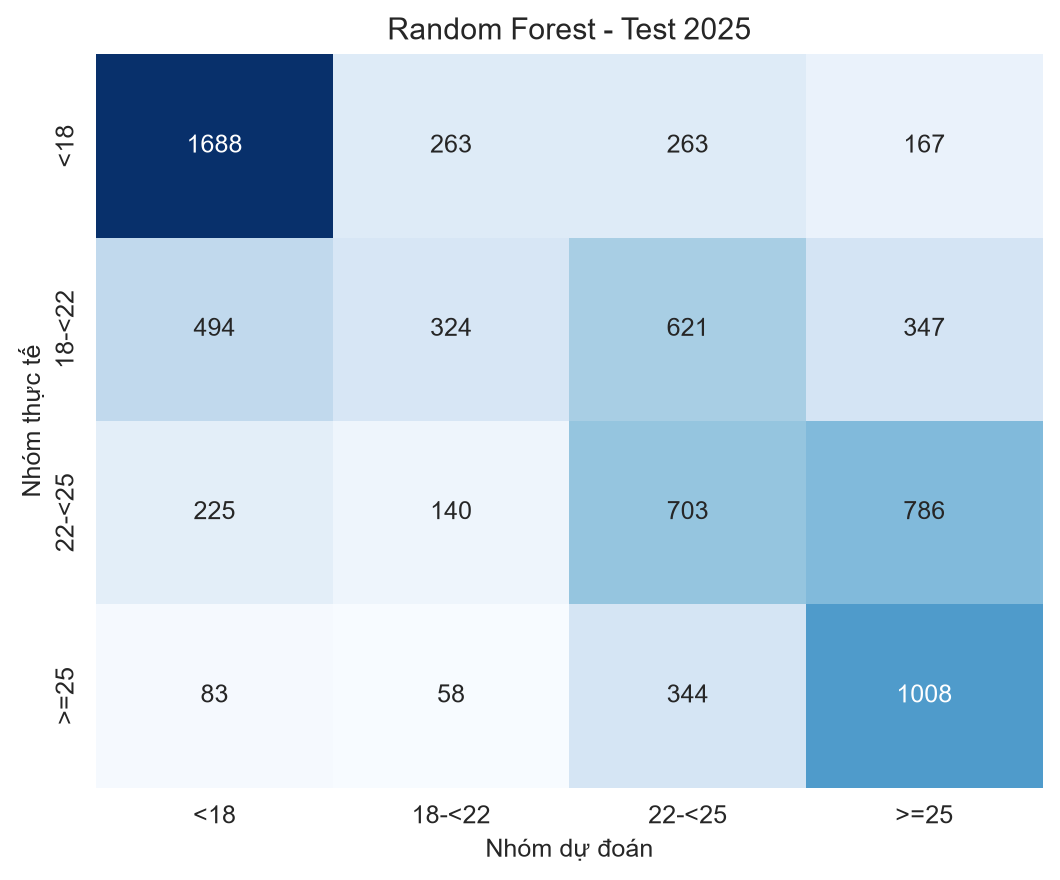

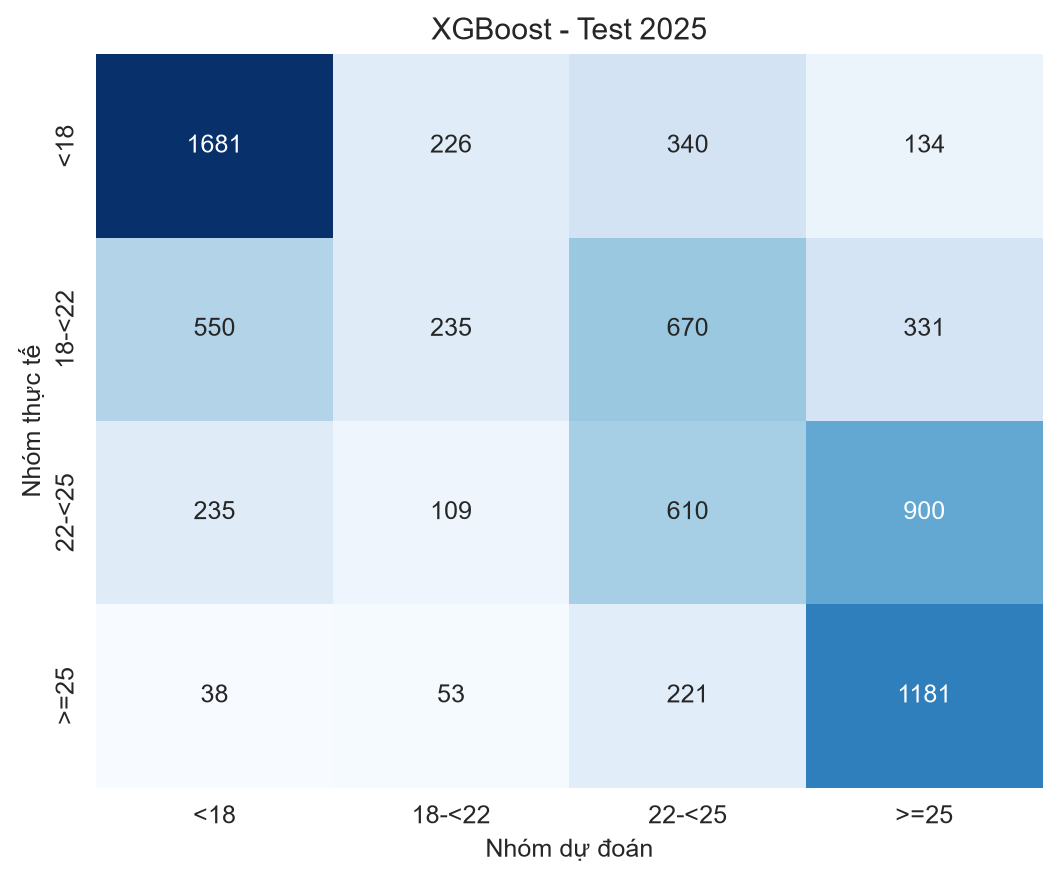

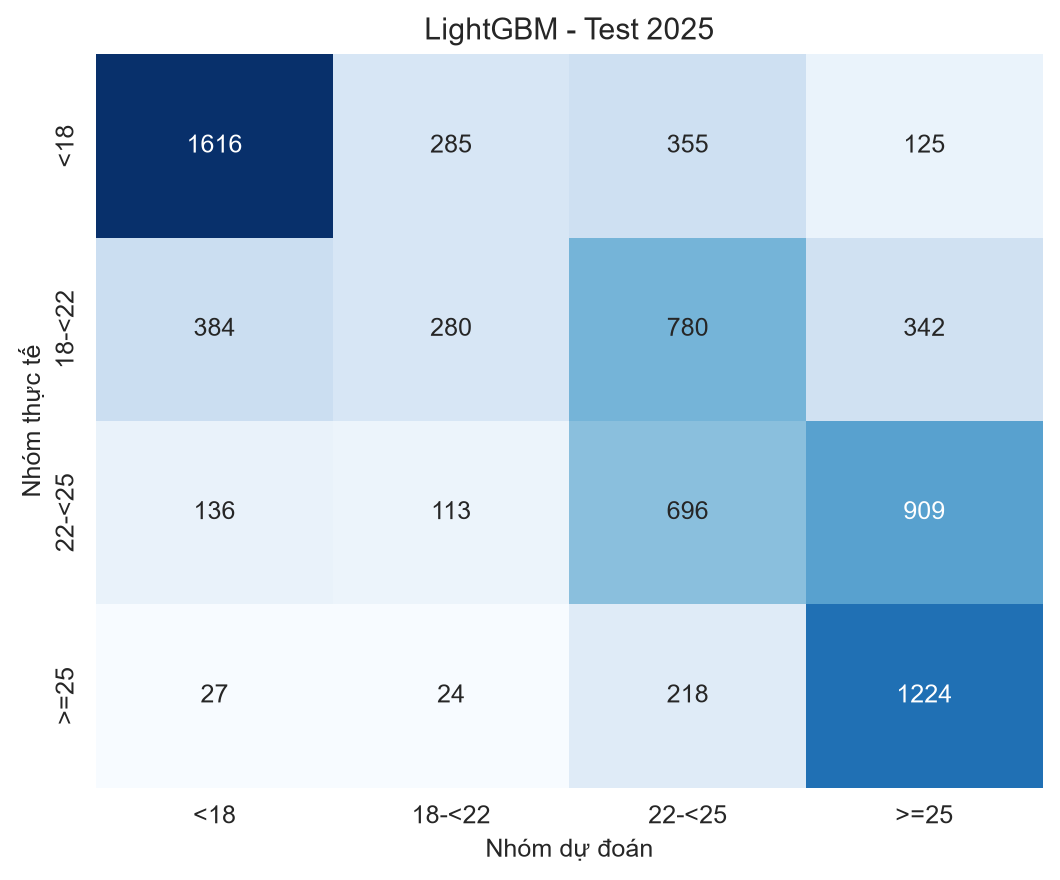

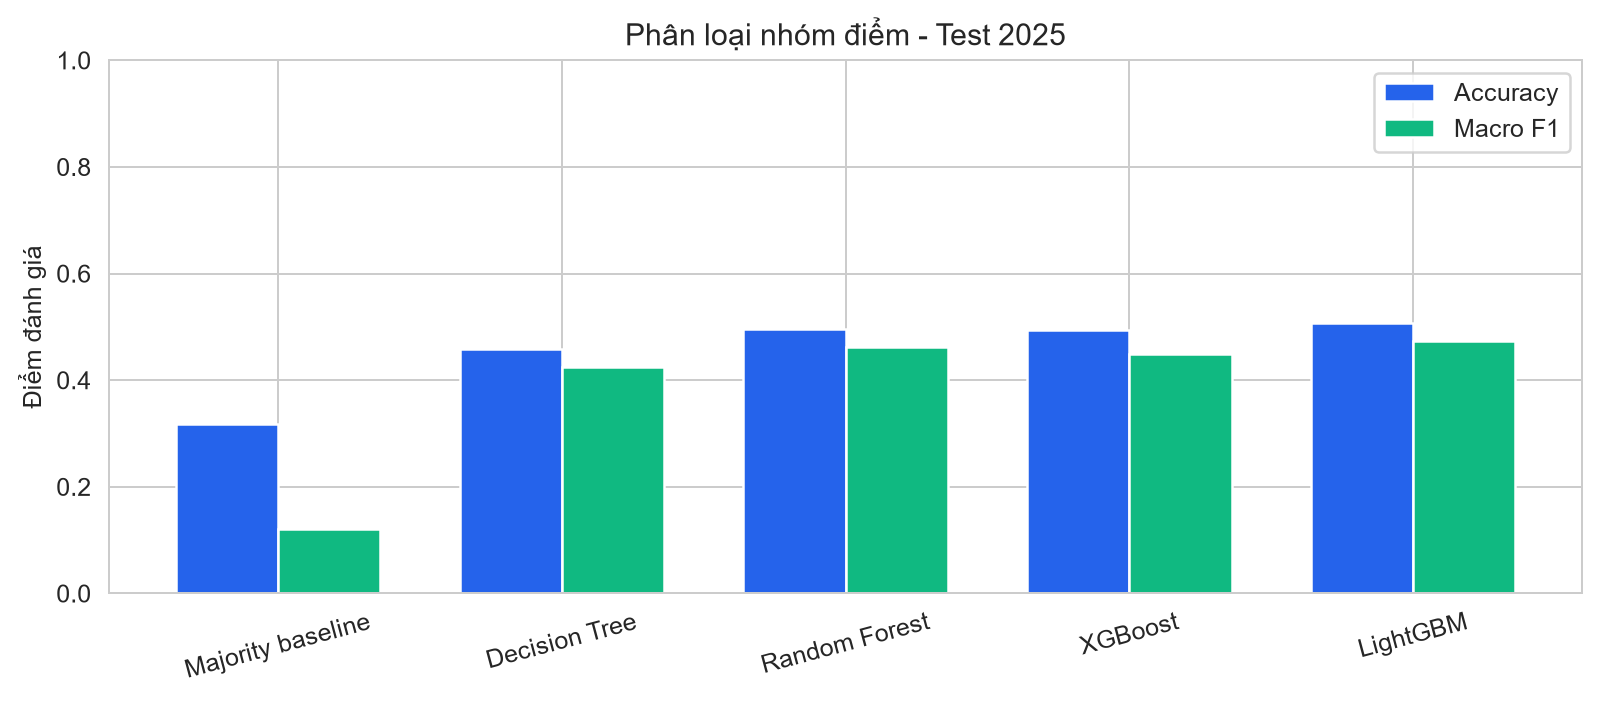

,Model,Class,Support,Recall
0,Decision Tree,Dưới 18,2381,0.618228
1,Decision Tree,Từ 18 đến dưới 22,1786,0.112542
2,Decision Tree,Từ 22 đến dưới 25,1854,0.411543
3,Decision Tree,Từ 25 trở lên,1493,0.678500
4,Random Forest,Dưới 18,2381,0.708946
5,Random Forest,Từ 18 đến dưới 22,1786,0.181411
6,Random Forest,Từ 22 đến dưới 25,1854,0.379180
7,Random Forest,Từ 25 trở lên,1493,0.675151
8,XGBoost,Dưới 18,2381,0.706006
9,XGBoost,Từ 18 đến dưới 22,1786,0.131579


In [19]:
for name in ['Decision Tree','Random Forest','XGBoost','LightGBM']:
    filename = '07_confusion_'+name.lower().replace(' ','_')+'.png'
    display(Image(filename=str(output_dir/'images'/filename),width=650))
display(Image(filename=str(output_dir/'images/08_classification_comparison.png'),width=850))
display(class_report)

*Hình 5.23–5.27. Ma trận nhầm lẫn và so sánh phân loại.*

### Bước 20. Nhị phân điểm từ 24 trở lên

Đánh giá riêng bài toán nhận diện các quan sát có điểm chuẩn từ 24 trở lên bằng đường cong ROC và chỉ số ROC AUC. Nhãn nhị phân này được xem xét độc lập với hệ thống phân loại bốn nhóm điểm.

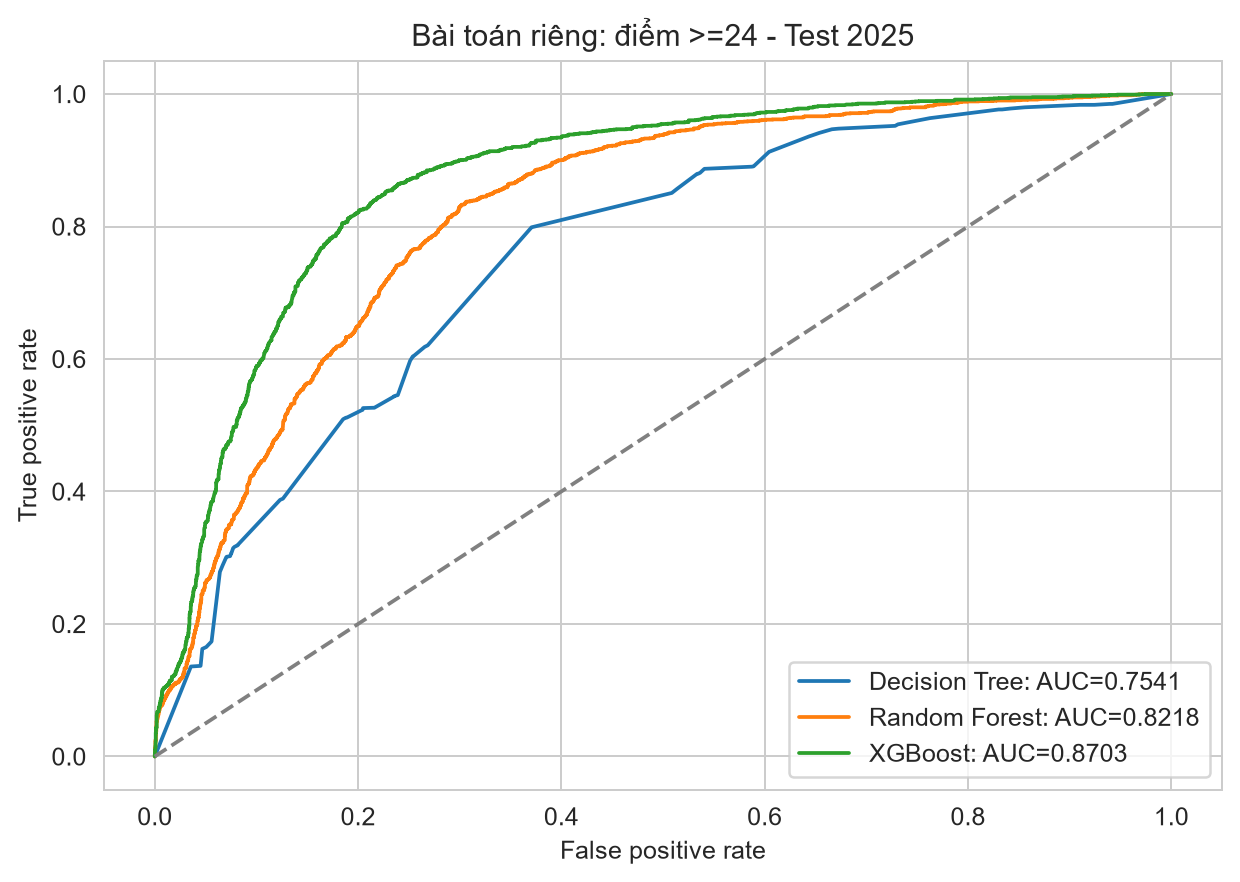

,Model,Accuracy,Macro F1,ROC AUC
8,Decision Tree,0.718126,0.657841,0.754129
9,Random Forest,0.756455,0.715731,0.821814
10,XGBoost,0.806228,0.781230,0.870296


In [20]:
display(Image(filename=str(output_dir/'images/09_binary_roc.png'),width=750))
display(test_metrics.loc[test_metrics.Task.eq('binary'),['Model','Accuracy','Macro F1','ROC AUC']])

*Hình 5.28. Đường cong ROC của bài toán nhị phân.*

### Bước 21. Tầm quan trọng đặc trưng

Sử dụng Permutation Importance trên tập xác thực năm 2024 để đo mức tăng MAE khi xáo trộn từng đặc trưng. Kết quả thể hiện đóng góp dự đoán trong mô hình, không được diễn giải là bằng chứng về quan hệ nhân quả.

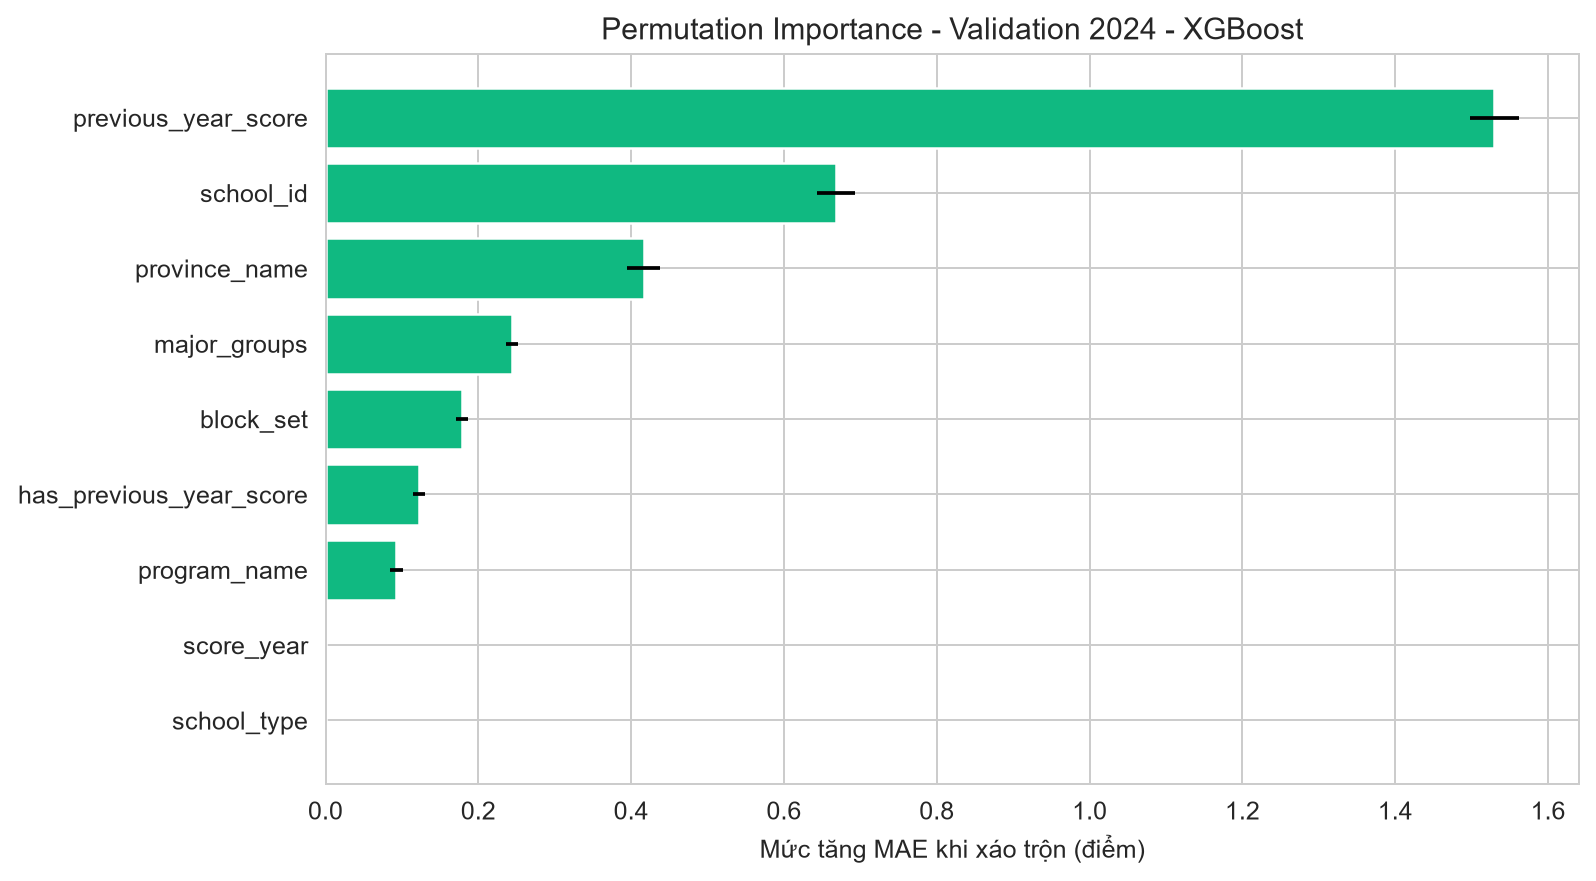

,Feature,MAE increase,Std
7,previous_year_score,1.529907,0.032244
0,school_id,0.667837,0.025018
2,province_name,0.416458,0.021464
4,major_groups,0.243688,0.008056
5,block_set,0.178159,0.007748
8,has_previous_year_score,0.122922,0.007872
3,program_name,0.092811,0.008262
1,school_type,0.000000,0.000000
6,score_year,0.000000,0.000000


Đóng góp dự đoán trong mô hình; không chứng minh quan hệ nhân quả.


In [21]:
display(Image(filename=str(output_dir/'images/10_validation_feature_importance.png'),width=850))
display(importance.sort_values('MAE increase',ascending=False))
print('Đóng góp dự đoán trong mô hình; không chứng minh quan hệ nhân quả.')

*Hình 5.29. Permutation Importance trên validation 2024.*

### Bước 22. Tổng hợp kết quả thực nghiệm

Tổng hợp thông tin dữ liệu, giao thức thực nghiệm, mô hình được lựa chọn và các chỉ số đánh giá vào tệp kết quả. Kết luận được xây dựng từ số liệu thực tế, đồng thời nêu rõ phạm vi áp dụng và các hạn chế của nghiên cứu.

In [22]:
summary = export_summary(df,audit,splits,validation_metrics,test_metrics,winners,importance,output_dir)
best = test_metrics.loc[test_metrics.Task.eq('regression')&test_metrics.Model.eq(winners['regression'])].iloc[0]
print(f"Mô hình chọn bằng validation: {winners['regression']}; test 2025 MAE={best.MAE:.4f}, RMSE={best.RMSE:.4f}, R²={best.R2:.4f}.")
for limitation in summary['limitations']: print('-',limitation)

Mô hình chọn bằng validation: XGBoost; test 2025 MAE=2.6022, RMSE=3.1744, R²=0.4620.
- Thực nghiệm ngoại tuyến trên dữ liệu lịch sử, không phải thử nghiệm tương lai thời gian thực.
- Cột điểm quy đổi dựa trên công thức và ghi chú tuyển sinh hiện có.
- Ánh xạ nhóm ngành giữ trạng thái chưa xác định đối với các mã ngành chưa rõ ràng.
- Mã hóa thứ tự cho biến định danh tạo thứ tự ngầm định.
- Dữ liệu nghiên cứu giới hạn trong thang điểm [10, 30] của phương thức THPT.
- Độ quan trọng đặc trưng thể hiện mối liên hệ tương quan, không mang tính nhân quả tuyệt đối.


*Kết quả tổng hợp và giới hạn của thực nghiệm.*

## 5.6. Kết luận và hướng phát triển

Thực nghiệm xây dựng quy trình tiền xử lý có truy vết, phân chia dữ liệu theo thời gian, lựa chọn mô hình trên tập xác thực và đánh giá trên tập kiểm tra năm 2025. Kết quả được đối chiếu với các mô hình cơ sở. Hướng phát triển gồm xác minh quy tắc quy đổi điểm theo từng cơ sở đào tạo, hoàn thiện định danh chương trình qua các năm và bổ sung chỉ tiêu tuyển sinh, số nguyện vọng, phân bố điểm thi. Khả năng ứng dụng cần tiếp tục được kiểm chứng bằng dữ liệu tương lai độc lập.

## Tài liệu tham khảo

[1] scikit-learn. Common pitfalls and recommended practices. https://scikit-learn.org/stable/common_pitfalls.html

[2] scikit-learn. RandomForestRegressor API reference. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

[3] XGBoost. Python API reference. https://xgboost.readthedocs.io/en/stable/python/python_api.html

[4] LightGBM. LGBMClassifier API reference. https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html